# VLA 方向周报：2026-11-09 至 11-15

**仓库：** `affordance-vla` · **范围：** 上一周（11-09 周一至 11-15 周日）的全部工作，外加本周一（11-16）已经开始的部分 · **写于：** 2026-11-16

这份 notebook 有两个用途：一是把一周里做过的事、得到的数字按时间和主题理清楚（细节）；二是回到研究目标，看现在离一篇能投出去的论文还差什么（大局）。

- **数字从哪来：** 表格和图都是从服务器上已经跑完的结果读出来的（rollout 的汇总文件、日志、训练记录），执行时现算，不是手抄。文字里引用的数字和表格一致。
- **ORACLE 的含义：** 仿真里的真值。凡是"真值计划"都是 ORACLE，它是上限，不是方法的结果。用模型预测的计划时，运行时从仿真拿的只有相机标定。
- **时间：** 日期按服务器时间（北京时间）。

## 0 · 一页总结

**研究目标（11-12 收束后的论点）：** affordance 只有在动作被训练成服从它时才对 VLA 有用。做法是"反事实 affordance 监督"：同一帧图像，把 affordance（接触点和接近方向）换到别处，动作标签按换过的路径改写；VLA 从图像预测 affordance，再由服从它的动作头执行。按 NeurIPS 2027 的要求设计，2027 年 1 月底设检查点，2 月中只有 LIBERO 系列结果就投 IROS 2027 的窄版本。

**这一周最重要的五个结果：**

1. **动作头只有用"换过的计划"训练才会服从计划**（六任务集，真值计划）。只把计划当输入、或者按 Fast Plans 的做法加噪声、随机丢弃、注入每一层（2.6 亿参数），都和"只用示范"一样。
2. **从图像预测计划，要对图像格子打分，不能直接回归坐标。** 回归坐标的计划头记住的是布局：物体换了位置，它 20 次里 20 次指向别的物体，闭环和官方权重一样（0/200）。对 8 × 8 个图像格子打分的计划头（VLM 分辨率下的 affordance map）在同样的帧上误差中位数 1.9 厘米。
3. **按论文协议，完整流程不用真值计划：位置扰动 0.660 ± 0.012，任务扰动 0.681 ± 0.012**（LIBERO-PRO Object，每个任务 50 个起始状态，3 个种子）。官方权重是 0.000 和 0.090，真值计划上限是 0.920 和 0.753。已发表的数字：GAM 0.47、0.50，CounterAlign 0.51、0.26，π0.5 加测试时 affordance 场 0.73（只有位置扰动）。
4. **"换过的计划"的动作标签怎么构造很关键。** 三处改动（先对齐再下降、搬运和释放阶段的反事实、标签修正）把高物体被碰倒的次数从 33、52 降到 8、19；后来诊断出任务扰动的三个失败任务是标签绕远路、抄错最后一段接近方式造成的，新的路径规则把任务扰动从 152 提到 166（真值计划）。
5. **计划保持比每次都重新预测好**（图像格子计划头：72、90 → 102、113 / 200）：计划头只见过示范画面，手臂一动画面就变了。

**一句话说现状：** LIBERO-Object 一个任务集上，"预测 affordance + 服从它的动作头"已经明显超过官方权重和两篇已发表的方法；但离"一种 VLA 训练方法"的完整论文还差：同一个 backbone 下的对比基线、训练种子、其余三个任务集、VLA 全量训练、第二个架构（第 6 节）。

**本周一（11-16）已经开始：** 新路径规则的检验（任务扰动 +14、+15 / 200，但位置扰动下 tomato sauce 用预测计划从 13 掉到 2），项目负责人决定新规则设为默认；正在训练"给换物体的样本加大计划噪声"的动作头；计划头误差的拆分（第 3.6 节）。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))
from affordance3d.plan_grid import camera_of_log
from affordance3d.plan_input import offsets_from_json
from affordance3d.rollout_log import load_rollout_log
from report import libero_pro_helpers as L
from report import plan_following_helpers as F
from report import plan_predictor_helpers as P
from report import weekly_helpers as W

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90, "font.family": ["DejaVu Sans", "Droid Sans Fallback"]})  # CJK fallback
pd.set_option("display.max_colwidth", 80)
RUNS = ROOT / "runs"
PRO, SIX = RUNS / "libero_pro", RUNS / "plan_following"
SUITES = {"位置扰动": "libero_object_swap", "任务扰动": "libero_object_task"}
offsets = offsets_from_json((SIX / "dataset10" / "offsets.json").read_text())


def show_counts(table):
    rates = [column for column in table.columns if column.endswith("rate")]
    display(table.style.format({column: "{:.2f}" for column in rates}, na_rep="–"))

## 1 · 研究问题是怎么一步步收窄的

**周初（11-10，Pipeline v2）的设想：** 让 VLA 预测"接触点 – 接近方向 – 路径点"计划（CAW），用可微的一致性损失约束动作和计划一致，再加 episode 内的轻量 affordance 状态，在杂乱桌面仿真里提高成功率。

**11-11 的计划跟随实验改变了重点：**
- 只把计划当额外输入，动作头不理它：示范里计划说的事，图像都已经说了。
- 训练时加入"换过的计划"，动作头就跟着计划走。
- 用"改写动作标签"和用"可微一致性损失"效果相当，前者命令更平滑。所以一致性损失不再是主要贡献。

**11-12 项目评审后的三个决定（项目负责人）：**
1. 论点收束为"affordance 只有在动作被训练成服从它时才有用"；一致性损失降为对照，episode 状态移出主线，统一的 CAW 计划只是接口。
2. 按 NeurIPS 2027 设计，2027 年 1 月底检查点，IROS 2027 作为退路。
3. 主对比做一组全量微调，其余消融用轻量训练（约 3100 万参数）。

**同一天的近邻核实（R9）把贡献的位置定得更窄：**
- "动作头会绕过冗余的计划"已经有人报告过（Fast Plans, Faithful Actions），不能当贡献；做法最接近的是 SIDO（图像不变、改位置输入、解析地改写动作，但不是 VLA、没有语言、不换目标）。
- 贡献要落在两点：反事实 affordance 监督和已有修法的正面比较；预测的 affordance 在 LIBERO-PRO 位置和任务扰动上的结果（GAM、CounterAlign 是标杆）。

**现在的系统（诊断规模）：**

```text
两张相机图像 + 指令
      │
冻结的 VLM（starVLA Qwen3-VL-4B 官方权重，36 层隐状态）
      │
      ├── 计划头（约 790 万参数）：给第三人称相机的 8×8 个图像 token 打分 + 格内位置 + 深度
      │        → 下一次夹爪事件（抓取 / 释放）的接触点和接近方向
      │        → 计划保持：接触点按世界坐标存下，直到夹爪完成这次事件
      │
      └── 动作头（DiT + LoRA + 计划编码器，约 3075 万参数），用"换过的计划"和改写的动作标签训练
               → 8 步动作块
```

训练用的数据只有标准 LIBERO-Object 的示范（10 个任务，454 条）；评测在 LIBERO-PRO 上，训练时从没见过那些扰动。

## 2 · 一周时间线

| 日期 | 做了什么 | 主要产出 |
| --- | --- | --- |
| 11-09 一 | 记忆方向的原型（RGB-D 几何、DINOv2 特征、体素记忆、SceneFun3D），组会数据集汇报 | `report/2026-11-09_datasets_report.ipynb` |
| 11-10 二 | VLA 方向起步：检索清单、Pipeline v1 → v2、R1–R3 核实；LIBERO 读取与 CAW 标签；A6000 服务器搭建（V0）；从 affordance3D 拆出本仓库，工作副本搬到服务器、大文件放 NAS | Pipeline v2、R1–R3、V0 记录；`2026-11-10_vla_datasets_sim_report`、`2026-11-10_vla_pipeline_demo` |
| 11-11 三 | 仿真环境、逐步记录的 rollout、官方权重探针；计划输入、换过计划的样本、计划条件动作头；**计划跟随实验** | `2026-11-11_plan_following_experiment`、实验记录 |
| 11-12 四 | 深度记录、真值 affordance map、**流程逐步演示**；项目评审 → 论点收束；R9 近邻核实；噪声加丢弃对照（负结果） | `2026-11-11_affordance_pipeline_walkthrough`、R9 |
| 11-13 五 | LIBERO-PRO 评测框架；**真值计划上限**；回归计划头（记住布局）→ **图像格子计划头**；计划保持与计划审计；深层注入对照（负结果）；释放阶段反事实；先对齐规则与标签修正；三处改动的归因 | `2026-11-12_libero_pro_object`、`2026-11-13_plan_predictor` |
| 11-14 六 | 新标签的十任务动作头（当时最好）；评测脚本加种子；**按论文协议**的 9 组运行 | 十任务结果 |
| 11-15 日 | 论文协议结果；**任务扰动三个失败任务的诊断** | `2026-11-14_libero_pro_full_protocol`、`2026-11-15_task_perturbation_failures`、诊断记录 |
| 11-16 一（本周） | 新路径规则的检验；新规则设为默认；开始训练"加大计划噪声"的动作头 | `2026-11-16_label_fix_results` |

上一周（11-09 至 11-15）共 45 个提交，本周一又有 3 个；仓库现在有 378 个单元测试。

## 3 · 关键结果（细节）

### 3.1 动作头会不会跟着计划走（六任务集，11-11 至 11-13）

**设置：** 官方权重，VLM 冻结；只训练计划编码器、DiT 的 LoRA 和动作解码器（约 3075 万参数），六个 LIBERO-Object 任务的示范，2400 步。闭环里给 ORACLE 计划。三组条件：标准起始状态（5 次）、目标挪动 4–16 厘米（18 次）、指令换成另一个物体（30 次）。成功 = 指令所说的物体第一个被夹住并最后在篮子里。

**状态：** 真实的 rollout；计划是 ORACLE。

In [2]:
SIX_RUNS = {"只用示范": "s2_none", "换计划 + 路径一致性损失": "s2_other", "换计划 + 改写动作标签": "s2_actions",
            "对照：计划加噪声 + 随机丢弃": "s3_noise", "对照：噪声 + 丢弃 + 注入每一层": "s5_deep"}


def rollout_folders(run):
    return [folder for folder in (SIX / run / "rollouts_oracle", SIX / run / "rollouts_oracle_more") if folder.is_dir()]


six = {name: F.merge_runs(*[F.load_run(folder) for folder in rollout_folders(run)]) for name, run in SIX_RUNS.items()}
table = F.success_table(six)
table.index = ["标准（5 次）", "目标挪动 4–16 厘米（18 次）", "指令换成另一个物体（30 次）"]
table.loc["训练的参数（百万）"] = [F.facts_table({name: SIX / run}).loc["trained_parameters_millions", name]
                                    for name, run in SIX_RUNS.items()]
display(table)

,只用示范,换计划 + 路径一致性损失,换计划 + 改写动作标签,对照：计划加噪声 + 随机丢弃,对照：噪声 + 丢弃 + 注入每一层
标准（5 次）,5 / 5,5 / 5,5 / 5,5 / 5,5 / 5
目标挪动 4–16 厘米（18 次）,8 / 18,12 / 18,15 / 18,7 / 18,6 / 18
指令换成另一个物体（30 次）,6 / 30,19 / 30,20 / 30,6 / 30,6 / 30
训练的参数（百万）,30.75,30.75,30.75,30.75,260.13


- **只有换过的计划能让动作头服从计划。** 两种"换计划"的做法在扰动条件下都明显高于"只用示范"（目标挪动 15/18 和 12/18 对 8/18，换物体 20/30 和 19/30 对 6/30）。
- **已发表的修法在这里不起作用。** Fast Plans, Faithful Actions 的三项（计划加噪声、随机丢弃、注入每一层）都做了，结果和"只用示范"一样；注入每一层时训练的参数多了八倍。这是我们按论文描述自己实现的版本，结论限于这个动作头和这种计划输入。
- 深层注入的对照被队列重跑过一次，目录里是第二次训练（目标挪动 6/18，第一次 7/18）。

### 3.2 LIBERO-PRO Object：从真值计划到预测的计划（11-13 至 11-16）

**设置：** LIBERO-PRO 的 Object 任务集，两种扰动——位置扰动（目标和另一个物体互换位置，指令不变）和任务扰动（指令和目标换成场景里另一个物体）。每个任务 20 个起始状态、种子 7，共 200 次 / 扰动。成功按 benchmark 自己的判定。

**状态：** 真实的 rollout。标"真值计划"的行用 ORACLE 计划；其余行的计划由计划头从图像预测。

**表中各行的含义：**
- 动作头："11 日"= 六个任务、旧标签；"13 日"= 六个任务、先对齐 + 释放反事实 + 标签修正；"十任务"= 同样的 13 日标签、十个任务都训练；"15 日规则"= 以起点为中心缩放路径、最后一段用该物体自己的接近方式。
- 计划："回归坐标"和"图像格子"是两种计划头；"每次查询"= 每 8 步重新预测，"保持"= 预测一次保持到夹爪完成事件。

In [3]:
PROGRESSION = {
    "官方权重，不给计划": "released",
    "回归坐标，每次查询（11 日动作头）": "predicted_p1",
    "回归坐标，保持（11 日动作头）": "predicted_p1_hold",
    "图像格子，每次查询（11 日动作头）": "predicted_g1",
    "图像格子，保持（11 日动作头）": "predicted_g1_hold",
    "图像格子，保持（13 日动作头）": "predicted_g1_hold_s8",
    "图像格子，保持（十任务动作头）": "predicted_g1_hold_s9",
    "图像格子，保持（十任务，15 日规则）": "predicted_g1_hold_s10",
    "真值计划（11 日动作头）": "oracle_plan_s2",
    "真值计划（13 日动作头）": "oracle_plan_s8",
    "真值计划（十任务动作头）": "oracle_plan_s9",
    "真值计划（十任务，15 日规则）": "oracle_plan_s10",
}
progression = W.count_table(PROGRESSION, PRO, SUITES)
show_counts(progression)

,位置扰动,位置扰动 rate,任务扰动,任务扰动 rate
官方权重，不给计划,0 / 200,0.00,20 / 200,0.10
回归坐标，每次查询（11 日动作头）,0 / 200,0.00,19 / 200,0.10
回归坐标，保持（11 日动作头）,0 / 200,0.00,53 / 200,0.27
图像格子，每次查询（11 日动作头）,72 / 200,0.36,90 / 200,0.45
图像格子，保持（11 日动作头）,102 / 200,0.51,113 / 200,0.56
图像格子，保持（13 日动作头）,113 / 200,0.56,130 / 200,0.65
图像格子，保持（十任务动作头）,133 / 200,0.67,136 / 200,0.68
图像格子，保持（十任务，15 日规则）,129 / 200,0.65,151 / 200,0.76
真值计划（11 日动作头）,164 / 200,0.82,136 / 200,0.68
真值计划（13 日动作头）,175 / 200,0.88,141 / 200,0.70


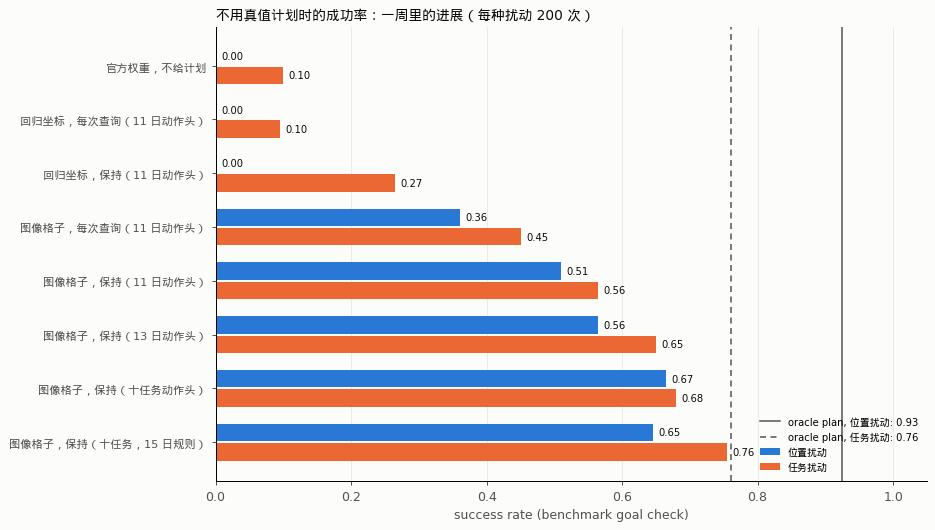

In [4]:
predicted = progression.loc[[name for name in PROGRESSION if not name.startswith("真值")]]
bounds = {column: progression.loc["真值计划（十任务动作头）", f"{column} rate"] for column in SUITES}
W.progression_figure(predicted, tuple(SUITES), bounds,
                     title="不用真值计划时的成功率：一周里的进展（每种扰动 200 次）")
plt.show()

**怎么读这张图：** 从上到下大致是时间顺序。
- **回归坐标的计划头不能用**（位置扰动 0）：它记住的是物体平常在哪。
- **换成图像格子的计划头是最大的一步**（0 → 72），**计划保持**再加一截（72 → 102）。
- **动作头的标签改进**（13 日、十任务）继续往上推，到 133 和 136。
- **15 日的路径规则**让任务扰动到 151，但位置扰动略降（133 → 129），原因在 3.5 节。
- 两条竖线是同一个十任务动作头给真值计划时的成功率，即计划头完全准确时能到的上限。

### 3.3 按论文协议的结果（11-14 至 11-15）

**设置：** 每个任务 50 个起始状态（论文的协议），两种扰动，种子 7、8、9（改变的是策略的采样噪声和仿真，每个配置只训练了一个模型）。每个配置、每种扰动共 1500 次。

**状态：** 真实的 rollout；第三行给 ORACLE 计划。

In [5]:
FULL = {"官方权重，不给计划": "full_released_seed{}", "十任务动作头 + 图像格子计划保持": "full_g1_hold_s9_seed{}",
        "十任务动作头 + 真值计划": "full_oracle_s9_seed{}"}
rows = {}
for name, pattern in FULL.items():
    for label, suite in SUITES.items():
        counts = [W.summary_counts(PRO / pattern.format(seed), suite) for seed in (7, 8, 9)]
        rates = [done / total for done, total in counts]
        rows[(name, label)] = {f"种子 {seed}": f"{done} / {total}" for seed, (done, total) in zip((7, 8, 9), counts)}
        rows[(name, label)] |= {"均值": np.mean(rates), "种子间标准差": np.std(rates, ddof=1)}
display(pd.DataFrame.from_dict(rows, orient="index").style.format({"均值": "{:.3f}", "种子间标准差": "{:.3f}"}))

**和已发表数字的关系**（Object 任务集；引用，没有重跑）：

In [6]:
display(L.published_table())

,what it is,position (Spatial / Object / Goal / LIBERO-10),task (Spatial / Object / Goal / LIBERO-10)
"π0.5, as reported in the GAM paper",official checkpoint,0.20 / 0.17 / 0.38 / 0.08,0.01 / 0.01 / 0.00 / 0.01
"π0.5, as reported in the CounterAlign paper",trained on LIBERO,0.53 / 0.19 / 0.29 / 0.06,0.55 / 0.10 / 0.17 / 0.17
GAM (arXiv 2609.23863),"not a VLA; 3D detector, simulator depth",0.60 / 0.47 / 0.19 / 0.05,0.88 / 0.50 / 0.16 / 0.08
CounterAlign (arXiv 2608.21740),π0.5 + offline RL,0.60 / 0.51 / 0.41 / 0.11,0.63 / 0.26 / 0.46 / 0.29
π0.5 + Affordance Field Intervention (arXiv 2512.07472),test-time depth and GPT-4o,0.76 / 0.73 / – / –,– / – / – / –


- **20 个起始状态时的结果站得住**（当时 0.67、0.68），种子间只差约 1 个百分点。
- **不用真值计划时高于 GAM 和 CounterAlign**（两种扰动都是），**位置扰动低于 π0.5 加测试时 affordance 场（0.73）**。
- **这不是同条件下的方法比较：** 底座模型不同（我们是 starVLA 的 Qwen3-VL-4B 权重，其余基于 π0.5 或不是 VLA）；GAM 和 affordance 场方法测试时用深度，我们的计划头用仿真里的相机标定；我们自己的官方权重在位置扰动下是 0.00，而论文里的 π0.5 是 0.17–0.19。
- **剩下的差距：** 位置扰动下在计划头（真值计划时 10 个任务里 7 个 ≥ 141/150）；任务扰动下在动作头（番茄酱瓶、牛奶、橙汁给真值计划也失败）——这引出了 3.5 节的诊断。

### 3.4 动作标签的三处改动，各自起了什么作用（11-13）

**问题：** 给真值计划时，剩下的失败多是高的物体被碰倒（夹爪还在旁边就开始下降，因为标签里的平移在最后一段之前一次塞进去）、夹住后在篮子外松开（换过的计划只覆盖了去抓取那一段）。

**三处改动：** "先对齐"（平移放不进路径前半段时先走完平移、再按示范的方式下降）；搬运和释放阶段的反事实；标签修正（挪动后的路径比示范剩下的步数长时，多出来的几步原来会叠加示范抓取后的抬起动作）。

**状态：** 真实的 rollout，ORACLE 计划，20 个起始状态、种子 7。

In [7]:
ATTRIBUTION = {"11 日动作头": "oracle_plan_s2", "只做标签修正": "oracle_plan_s2b",
               "只加释放阶段反事实（修正前）": "oracle_plan_s6", "先对齐 + 标签修正": "oracle_plan_s7",
               "三处都改（13 日）": "oracle_plan_s8", "十任务，旧标签": "oracle_plan"}
attribution = W.count_table(ATTRIBUTION, PRO, SUITES)
for label, suite in SUITES.items():
    stages = {name: L.stage_counts(PRO / run, suite) for name, run in ATTRIBUTION.items()}
    attribution[f"{label}：碰倒"] = [s["object knocked over before it was held"] for s in stages.values()]
    attribution[f"{label}：篮子外松开"] = [s["held, then let go outside the basket"] for s in stages.values()]
show_counts(attribution)

,位置扰动,位置扰动 rate,任务扰动,任务扰动 rate,位置扰动：碰倒,位置扰动：篮子外松开,任务扰动：碰倒,任务扰动：篮子外松开
11 日动作头,164 / 200,0.82,136 / 200,0.68,33,16,52,22
只做标签修正,159 / 200,0.80,130 / 200,0.65,36,21,49,32
只加释放阶段反事实（修正前）,154 / 200,0.77,142 / 200,0.71,42,18,49,21
先对齐 + 标签修正,169 / 200,0.84,136 / 200,0.68,8,22,17,41
三处都改（13 日）,175 / 200,0.88,141 / 200,0.70,8,10,19,12
十任务，旧标签,157 / 200,0.79,131 / 200,0.66,14,12,14,31


- **碰倒次数的下降来自"先对齐"**（33、52 → 8、17）；标签修正单独不起作用。
- **释放阶段的反事实单独没用，和先对齐一起才有用**：先对齐之后夹住的多了，失败挪到搬运和释放（篮子外松开 22、41），释放反事实把它降到 10、12。
- 十个任务都训练、但用旧标签时，成功没有更高：起作用的主要是标签。

### 3.5 任务扰动三个失败任务的诊断，以及新路径规则的检验（11-15 至 11-16）

**诊断（只用已有日志）：**
- 番茄酱瓶、牛奶、橙汁三个任务大多是"悬停后时间用完"或被碰倒；同一个橙汁放在同一位置，位置扰动下能做成（121/150）。
- 原因在"换成另一个物体"的训练标签：这三个任务是要的物体离夹爪起点最近的三个，挪过去的示范路径是直线距离的 3.3–4.5 倍、还会先远离 14–18 厘米；而且最后一段抄的是场景原目标的接近方式（番茄酱瓶的示范是侧面低位进去，套到牛奶上就把牛奶碰倒）。

**新规则（15 日）：** 路径前半段以夹爪起点为中心旋转缩放、不再整体平移；最后一段取自要的物体自己的示范。CPU 上检查：十对场景里"先远离"都没了，三个失败任务的绕路比降到 1.7–2.1。

**检验：** 只有标签不同的两个十任务动作头，20 个起始状态、种子 7。

In [8]:
FIX = {"十任务（13 日标签）+ 真值计划": "oracle_plan_s9", "十任务（15 日规则）+ 真值计划": "oracle_plan_s10",
       "十任务（13 日标签）+ 图像格子保持": "predicted_g1_hold_s9", "十任务（15 日规则）+ 图像格子保持": "predicted_g1_hold_s10"}
fix_logs = {name: {suite: L.load_suite(PRO / run, suite) for suite in SUITES.values()} for name, run in FIX.items()}
show_counts(W.count_table(FIX, PRO, SUITES))
FOCUS = {"任务扰动": [3, 4, 6], "位置扰动": [5]}
for label, suite in SUITES.items():
    print(label, "（只列变化最大的任务）")
    display(L.per_task_table(fix_logs, suite).loc[FOCUS[label]])

,位置扰动,位置扰动 rate,任务扰动,任务扰动 rate
十任务（13 日标签）+ 真值计划,185 / 200,0.93,152 / 200,0.76
十任务（15 日规则）+ 真值计划,186 / 200,0.93,166 / 200,0.83
十任务（13 日标签）+ 图像格子保持,133 / 200,0.67,136 / 200,0.68
十任务（15 日规则）+ 图像格子保持,129 / 200,0.65,151 / 200,0.76


位置扰动 （只列变化最大的任务）


,instruction given,十任务（13 日标签）+ 真值计划,十任务（15 日规则）+ 真值计划,十任务（13 日标签）+ 图像格子保持,十任务（15 日规则）+ 图像格子保持
task,,,,,
5,pick up the tomato sauce and place it in the basket,19 / 20,20 / 20,13 / 20,2 / 20


任务扰动 （只列变化最大的任务）


,instruction given,十任务（13 日标签）+ 真值计划,十任务（15 日规则）+ 真值计划,十任务（13 日标签）+ 图像格子保持,十任务（15 日规则）+ 图像格子保持
task,,,,,
3,pick up the ketchup and place it in the basket,5 / 20,1 / 20,0 / 20,0 / 20
4,pick up the milk and place it in the basket,3 / 20,10 / 20,4 / 20,4 / 20
6,pick up the orange juice and place it in the basket,8 / 20,18 / 20,7 / 20,16 / 20


- **绕路的问题解决了：** 任务扰动真值计划 152 → 166，图像格子 136 → 151；橙汁 8 → 18、7 → 16。
- **牛奶只在真值计划下上升：** 用预测计划时，被碰歪的纸盒还在原位的保持计划里，夹爪去了空位。
- **番茄酱瓶到得更快，但问题挪到抓取和搬运。**
- **新动作头更严格地跟着计划走：** 位置扰动下 tomato sauce 的预测计划偏约 3 厘米，旧动作头还能找到罐子（13/20），新动作头走到计划点、什么也没抓到（2/20）。
- 项目负责人 11-16 决定：新规则设为默认，接着做"教动作头修正小的计划误差"（正在训练），再提高计划头精度。

### 3.6 计划头：从回归坐标到图像格子，以及误差还在哪里（11-13，11-16）

**离线测试**（计划头在没训练过的帧上，误差是预测接触点到 ORACLE 接触点的距离）：

In [9]:
metrics = {"回归坐标": P.load_metrics(RUNS / "plan_predictor" / "p1"),
           "图像格子": P.load_metrics(RUNS / "plan_predictor" / "g1")}
display(P.offline_table(metrics))

\
                                                            items   
held-out demonstrations, own instruction: next grasp           98   
held-out demonstrations, own instruction: next release         30   
held-out demonstrations, another object named                 490   
LIBERO-PRO start frames: another object asked for              20   
LIBERO-PRO start frames: target swapped with another object    20   

                                                                         回归坐标  \
                                                            median error (cm)   
held-out demonstrations, own instruction: next grasp                     1.13   
held-out demonstrations, own instruction: next release                   1.31   
held-out demonstrations, another object named                            2.71   
LIBERO-PRO start frames: another object asked for                        3.71   
LIBERO-PRO start frames: target swapped with another object             22.89   

                                                                         \
                                                            within 2 cm   
held-out demonstrations, own instruction: next grasp              0.878   
held-out demonstrations, own instruction: next release            0.833   
held-out demonstrations, another object named                     0.365   
LIBERO-PRO start frames: another object asked for                 0.400   
LIBERO-PRO start frames: target swapped with another object       0.000   

                                                                                   \
                                                            another object nearer   
held-out demonstrations, own instruction: next grasp                        0.020   
held-out demonstrations, own instruction: next release                      0.000   
held-out demonstrations, another object named                               0.222   
LIBERO-PRO start frames: another object asked for                           0.250   
LIBERO-PRO start frames: target swapped with another object                 1.000   

                                                                         \
                                                            event right   
held-out demonstrations, own instruction: next grasp               0.98   
held-out demonstrations, own instruction: next release             1.00   
held-out demonstrations, another object named                      0.98   
LIBERO-PRO start frames: another object asked for                  1.00   
LIBERO-PRO start frames: target swapped with another object        1.00   

                                                                         图像格子  \
                                                            median error (cm)   
held-out demonstrations, own instruction: next grasp                     0.61   
held-out demonstrations, own instruction: next release                   0.92   
held-out demonstrations, another object named                            1.08   
LIBERO-PRO start frames: another object asked for                        1.32   
LIBERO-PRO start frames: target swapped with another object              1.94   

                                                                         \
                                                            within 2 cm   
held-out demonstrations, own instruction: next grasp              0.939   
held-out demonstrations, own instruction: next release            1.000   
held-out demonstrations, another object named                     0.835   
LIBERO-PRO start frames: another object asked for                 1.000   
LIBERO-PRO start frames: target swapped with another object       0.550   

                                                                                   \
                                                            another object nearer   
held-out demonstrations, own instruction: next grasp                        0.031   
held-out demonstra

**闭环里第一个计划的误差拆分（11-16 新做）：** 按论文协议的 1500 次位置扰动 rollout，每次第一个预测计划相对 ORACLE 抓取点的误差，拆成沿相机视线的部分（深度估错）和垂直于视线的部分（格子选错或格内位置错）。

In [10]:
camera = camera_of_log(load_rollout_log(SIX / "demos" / "pick_up_the_salad_dressing_and_place_it_in_the_basket_demo0.npz"))
swap_logs = [log for seed in (7, 8, 9) for log in L.load_suite(PRO / f"full_g1_hold_s9_seed{seed}", "libero_object_swap")]
display(P.first_plan_split_table(swap_logs, offsets, camera))

,rollouts,error (cm),across the ray (cm),along the ray (cm),plan in the right cell
alphabet soup,150,1.4,0.9,1.1,100%
bbq sauce,150,3.0,1.5,2.6,74%
butter,150,7.7,6.3,2.7,36%
chocolate pudding,150,0.5,0.4,0.2,100%
cream cheese,150,1.9,0.9,1.7,80%
ketchup,150,1.6,0.7,1.3,100%
milk,150,1.9,0.9,1.5,100%
orange juice,150,1.9,1.8,0.5,100%
salad dressing,150,1.7,1.6,0.5,98%
tomato sauce,150,2.9,2.5,0.9,0%


- **整体上两部分差不多大**（中位数约 1 厘米左右），所以只改深度或只改格子都不够。
- **tomato sauce：** 150 次都不在对的格子里，误差几乎全在垂直于视线的方向——要改的是格子的选择，深度先验帮不上。
- **butter：** 只有约三分之一落在对的格子里，误差最大。
- **bbq sauce、cream cheese 等：** 沿视线的部分更大——一个便宜的改法是用该物体已知的抓取高度，把视线和那个高度的水平面相交，代替回归的深度。
- 下一步（第 7 节）的计划头改进按这个拆分来设计。

## 4 · 负结果和被放下的方向

| 方向 | 结果 | 处理 |
| --- | --- | --- |
| 计划只当额外输入 | 动作头忽略它（和只用示范一样） | 必须配反事实样本 |
| 可微一致性损失 | 和改写动作标签效果相当，命令更抖 | 降为对照（11-12） |
| 计划加噪声 + 随机丢弃（Fast Plans 前两项） | 和只用示范一样 | 作为对比基线保留 |
| 再加注入每一层（Fast Plans 第三项，2.6 亿参数） | 仍然一样 | 作为对比基线保留 |
| 回归坐标的计划头 | 记住布局，位置扰动 0/200 | 换成图像格子 |
| 每次查询都重新预测计划 | 比保持差（72、90 对 102、113） | 计划保持作为方法的一部分（11-13 决定） |
| 只加释放阶段反事实 | 单独没用 | 和先对齐一起用 |
| episode 状态 | 未做 | 移出主线（11-12） |
| 每个条件 2 个起始状态 | 结论会翻（2/6 对 6/6 后来变成 12/18 对 15/18） | 每个扰动条件至少 6 个起始状态 |

## 5 · 工程与基础设施

- **服务器：** 共享的 8 × A6000，作业全走别的项目的队列（一张卡一个作业、按文件名排优先级）；仿真只用 CPU、软件渲染。经验：别人的作业多时要用 `share=6`；只想要某张卡时只写那张卡；队列会自动重跑失败或被停掉的作业（会写同一个目录）；同时跑的仿真进程要限数。5 号卡这周基本空闲，比共享卡快 4–6 倍。
- **数据和代码：** 代码在服务器 `~/affordance-vla`，提交和推送都在那里；大文件在 NAS；本机只做查看。
- **评测框架：** LIBERO-PRO 的 fork 和任务文件、逐步记录的 rollout（含深度、计划、夹爪事件）、计划审计、计划保持、带种子的评测脚本。
- **测试：** 378 个单元测试；每次提交前跑提交前检查；写完代码请一个代理审查，审查出的问题都改了（包括两次会导致结论偏差的：高度表的物体位置、任务扰动指令的处理）。
- **意外：** 服务器网络 11-16 上午断过约 20 分钟；两次 GPU 显存被别人占满导致训练启动失败、换卡重提。

## 6 · 大局：离目标的研究范围还差什么

### 6.1 论点和要支撑的主张

| 主张 | 现在的证据 | 强度 | 还缺什么 |
| --- | --- | --- | --- |
| C1 动作头会绕过冗余的计划 | 计划跟随实验（六任务集） | 有，但不是我们的贡献（Fast Plans 已报告） | 只作动机 |
| C2 反事实 affordance 监督让动作服从计划，而已发表的修法不行 | 六任务集：换计划 15/18、20/30 对噪声/丢弃/注入 6–7/18、6/30 | 在这个设置里强 | 第二个架构；VLA 全量训练下再验证；LIBERO-PRO 上的同协议对比 |
| C3 从图像预测的 affordance + 服从它的动作头，对位置和任务扰动鲁棒 | Object：0.660、0.681（官方 0.000、0.090），三个种子 | Object 上强 | 其余三个任务集；同一 backbone 的基线；训练种子 |
| C4 反事实动作标签怎么构造很关键（先对齐、接近方式、路径缩放） | 碰倒 33、52 → 8、19；任务扰动 152 → 166 | 有，偏工程 | 系统的消融；可以写成方法的一节 |
| C5 是一种 VLA **训练方法**（不是冻结 VLA 外挂的模块） | **还没有**：现在 VLM 冻结、计划头和动作头是外加的 | 缺 | 把 affordance 头作为 VLA 的输出、全量训练 VLA 的主对比（11-12 已同意做一组） |

**C5 要特别注意：** 项目最初的要求是"VLA 用 affordance 结构训练后，闭环结果要好于同一个 backbone 按常规训练"，并且明确不接受冻结 VLA 外挂一个模块。现在所有结果都是诊断规模（VLM 冻结），用来定方法的形状；最终的主结果必须来自训练 VLA 本身。

### 6.2 审稿人最可能问的

1. **和 Fast Plans、SIDO、GAM、affordance 场方法的区别和正面比较**：要在同一个 backbone、同一协议下比，而不只是引用数字。
2. **同一 backbone 的基线**：官方权重是"常规训练"的一个基线，但还需要"同样数据、同样参数量、不用换计划"的动作头（只用示范）、以及 Fast Plans 修法，都在 LIBERO-PRO 上按论文协议跑。
3. **只有一个任务集、一个架构、一次训练。**
4. **运行时用了仿真的相机标定**：真实部署需要标定相机，这是常规假设，但要写清楚。
5. **真机实验**：NeurIPS 上的机器人论文常常需要；是否纳入范围要早定。

### 6.3 必须补的实验（我的排序）

| 优先级 | 实验 | 为什么 | 粗略代价 |
| --- | --- | --- | --- |
| P0 | 同 backbone 基线（只用示范的动作头、Fast Plans 修法）在 LIBERO-PRO Object 上按论文协议 | 没有它 C2、C3 站不住 | 训练已有，评测每组约 15 小时（共享卡） |
| P0 | LIBERO-Spatial（也是抓取–放置，计划定义不用改） | 第二个任务集，代价最低 | 数据回放 + 训练 + 评测，约 1 周 |
| P0 | 训练种子（动作头、计划头各 2 次） | 现在只有评测种子 | 每次训练约 1 小时（空闲卡） |
| P1 | VLA 全量训练的主对比（affordance 头作为 VLA 的输出） | C5，项目的核心要求 | 需要 8 卡时间段 |
| P1 | 计划头精度（格子选择 + 深度先验 / 腕部相机 / 闭环画面训练） | 位置扰动剩下的差距（0.66 对 0.92） | 每次几小时 |
| P1 | LIBERO-Goal、LIBERO-10（开抽屉、开炉子等非抓取–放置动作的计划定义） | 完整 benchmark | 设计 + 约 2 周 |
| P1 | 第二个架构（例如 π0.5） | 通用性 | 2 周以上 |
| P2 | LIBERO-PRO 的外观和语言扰动；真机 | 完整性 | 待定 |

## 7 · 时间规划（我的建议，等你确认）

离 2027 年 1 月底的检查点约 11 周。按两周一块：

| 时间 | 目标 |
| --- | --- |
| 11-16 – 11-29 | 完成"加大计划噪声"和计划头精度两项；番茄酱瓶的抓取搬运；LIBERO-Spatial 数据和计划；同 backbone 基线在 Object 上跑起来 |
| 11-30 – 12-13 | VLA 全量训练的主对比（需要 8 卡时间段）；Object + Spatial 按论文协议的完整表；训练种子 |
| 12-14 – 12-27 | 第二个架构起步；LIBERO-Goal / LIBERO-10 的计划定义 |
| 12-28 – 2027-01-10 | 其余任务集的结果；消融（标签规则、计划保持、map 对回归） |
| 01-11 – 01-31 | 写初稿；1 月底检查点：按 11-12 的约定决定 NeurIPS 还是 IROS |

**本周（11-16 起）具体：**
1. 等"加大计划噪声"的动作头结果（今晚），看 tomato sauce 能否恢复、任务扰动的提升能否保住。
2. 按 3.6 节的拆分改计划头：深度用"视线 ∩ 物体抓取高度的水平面"；格子选择用更细的输出或腕部相机。
3. 开始 LIBERO-Spatial：回放示范、建数据集、确认计划定义。
4. 同 backbone 基线：用已有的"只用示范"和 Fast Plans 对照动作头，在 LIBERO-PRO Object 上按论文协议跑。

## 8 · 需要你决定或关注的事

1. **下一个任务集先做 LIBERO-Spatial 吗？** 我的建议：是，它也是抓取–放置，计划定义不用改，最便宜地把结果扩到第二个任务集。
2. **同 backbone 的基线做哪几个？** 我的建议：只用示范的动作头、Fast Plans 修法（噪声 + 丢弃 + 注入每一层）、官方权重；三者都按论文协议。
3. **全量训练的 8 卡时间段什么时候能排？** 这决定 C5 的进度。
4. **真机是否在 NeurIPS 版本的范围内？** 影响 12 月以后的安排。

## 9 · 索引

**汇报 notebook（`report/`）：** `2026-11-09_datasets_report`、`2026-11-10_vla_datasets_sim_report`、`2026-11-10_vla_pipeline_demo`、`2026-11-11_plan_following_experiment`、`2026-11-11_affordance_pipeline_walkthrough`、`2026-11-12_libero_pro_object`、`2026-11-13_plan_predictor`、`2026-11-14_libero_pro_full_protocol`、`2026-11-15_task_perturbation_failures`、`2026-11-16_label_fix_results`。

**文档（`docs/vla/`）：** `README.md`（状态和全部决定）、Pipeline v2、R1–R3、V0 服务器记录、计划跟随实验（11-11）、R9 近邻核实（11-12）、预测计划驱动闭环（11-13，含论文协议 1.8 节）、任务扰动失败诊断（11-15，含修法检验第 3 节）。

**运行目录（服务器 NAS `runs/`）：** `plan_following/`（s1–s11 动作头）、`plan_predictor/`（p1 回归、g1 图像格子）、`libero_pro/`（全部闭环评测，含 `full_*` 论文协议的 9 组）。